**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**TC5053.10 · Ciencia y analítica de datos · Grupo 10**

Tecnológico de Monterrey

Profesora titular: Dra. Grettel Barceló  
Profesor tutor: Mtro. Roberto Antonio Guevara González

**Actividad 4 · Análisis exploratorio de datos**

---

* **NOMBRE:** Alejandro Santiago Baca Eyssautier
* **MATRÍCULA:** A01656580

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [14]:
from pathlib import Path
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid')

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [15]:
ruta_datos = Path('personal_loan.csv')
loan_df = pd.read_csv(ruta_datos).set_index('ID')

loan_df.info()

resumen_tipos = pd.DataFrame({
    'cantidad_columnas': [
        loan_df.select_dtypes(include='number').shape[1],
        loan_df.select_dtypes(include='object').shape[1]
    ]
}, index=['numéricas', 'texto'])

display(resumen_tipos)
display(loan_df.head())

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


,cantidad_columnas
numéricas,8
texto,5


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.600,1.000,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.500,1.000,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.000,1.000,0,0,0,0,0,0
3,35,9,100,94112,1,2.700,2.000,0,0,0,0,No,0
4,35,8,45,91330,4,1.000,2.000,0,0,No,No,0,1


**Respuesta.** Después de establecer `ID` como índice, el dataframe contiene **5,037 registros y 13 variables**. Pandas identifica **8 columnas numéricas** y **5 columnas de texto**. No se observan valores faltantes en esta carga inicial.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [16]:
resumen_numerico_inicial = loan_df.select_dtypes(include='number').describe().T
display(resumen_numerico_inicial)

criterios_invalidos = {
    'Age mayor a 100': loan_df['Age'].gt(100),
    'Experience negativa': loan_df['Experience'].lt(0),
    'ZIP Code sin cinco dígitos': loan_df['ZIP Code'].astype(str).str.len().ne(5),
    'Family fuera de 1 a 4': ~loan_df['Family'].isin([1, 2, 3, 4]),
    'Education fuera de 1, 2 o 3': ~loan_df['Education'].isin([1, 2, 3])
}

resumen_inconsistencias = pd.DataFrame({
    'registros': {nombre: int(mascara.sum()) for nombre, mascara in criterios_invalidos.items()}
})
display(resumen_inconsistencias)

mascara_invalida = np.logical_or.reduce(list(criterios_invalidos.values()))
registros_invalidos = loan_df.loc[mascara_invalida]
display(registros_invalidos)

registros_iniciales = len(loan_df)
loan_df = loan_df.loc[~mascara_invalida].copy()
registros_eliminados_limpieza = registros_iniciales - len(loan_df)
porcentaje_eliminado_limpieza = registros_eliminados_limpieza / registros_iniciales * 100

resultado_limpieza = pd.DataFrame({
    'valor': [registros_iniciales, registros_eliminados_limpieza, porcentaje_eliminado_limpieza, len(loan_df)]
}, index=['registros iniciales', 'registros eliminados', 'porcentaje eliminado', 'registros restantes'])
display(resultado_limpieza)

,count,mean,std,min,25%,50%,75%,max
Age,"5,037.000",45.411,11.647,23.000,35.000,45.000,55.000,144.000
Experience,"5,037.000",20.122,11.461,-3.000,10.000,20.000,30.000,43.000
Income,"5,037.000",73.898,46.131,8.000,39.000,64.000,98.000,224.000
ZIP Code,"5,037.000","93,152.866","2,119.638","9,307.000","91,911.000","93,437.000","94,608.000","96,651.000"
Family,"5,037.000",2.395,1.151,-3.000,1.000,2.000,3.000,4.000
CCAvg,"5,037.000",1.942,1.756,0.000,0.700,1.500,2.600,10.000
Education,"5,037.000",1.881,0.843,1.000,1.000,2.000,3.000,7.300
Mortgage,"5,037.000",56.501,101.658,0.000,0.000,0.000,101.000,635.000


,registros
Age mayor a 100,3
Experience negativa,53
ZIP Code sin cinco dígitos,1
Family fuera de 1 a 4,2
"Education fuera de 1, 2 o 3",1


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.400,3.000,0,0,0,0,No,0
15,60,30,22,95054,-1,1.500,3.000,0,0,No,0,Yes,Yes
89,25,-1,113,94303,4,2.300,3.000,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.700,2.000,0,0,No,0,No,0
250,144,6,29,94305,3,1.000,2.000,117,0,No,0,No,No
315,24,-2,51,90630,3,0.300,3.000,0,0,No,No,1,0
347,25,0,43,94305,2,1.600,7.300,0,0,Yes,Yes,1,Yes
384,51,25,21,9307,4,0.600,3.000,0,No,0,0,1,Yes
451,28,-2,48,94132,2,1.750,3.000,89,0,No,0,1,No


,valor
registros iniciales,"5,037.000"
registros eliminados,60.000
porcentaje eliminado,1.191
registros restantes,"4,977.000"


**Criterios de limpieza.** Se eliminaron tres edades superiores a 100 años porque son incompatibles con el perfil esperado de clientes y, además, no guardan coherencia con la experiencia laboral registrada. También se eliminaron 53 experiencias negativas, dos tamaños de familia negativos, un nivel educativo 7.3 fuera de las categorías 1–3 y un código postal de cuatro dígitos. Ninguna de estas anomalías se traslapa con otra, por lo que se retiraron **60 registros**, equivalentes a **1.191%** del dataframe original. No se eliminaron valores altos de ingreso, gasto o hipoteca porque, aunque son extremos, permanecen dentro de rangos financieramente posibles y deben analizarse como parte de la distribución.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [17]:
columnas_texto = loan_df.select_dtypes(include='object').columns.tolist()
display(loan_df[columnas_texto].describe().T)

for columna in columnas_texto:
    display(Markdown(f'**Frecuencias originales de {columna}**'))
    display(loan_df[columna].value_counts(dropna=False).to_frame('frecuencia'))

mapa_binario = {0: 0, 1: 1, '0': 0, '1': 1, 'No': 0, 'Yes': 1}
columnas_binarias = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

for columna in columnas_binarias:
    loan_df[columna] = loan_df[columna].map(mapa_binario).astype('int64')

for columna in columnas_binarias:
    display(Markdown(f'**Frecuencias unificadas de {columna}**'))
    display(loan_df[columna].value_counts(dropna=False).sort_index().to_frame('frecuencia'))

,count,unique,top,freq
Personal Loan,4977,4,0,3475
Securities Account,4977,4,No,2693
CD Account,4977,4,No,2462
Online,4977,4,Yes,1700
CreditCard,4977,4,0,2628


**Frecuencias originales de Personal Loan**

,frecuencia
Personal Loan,
0,3475
No,1017
Yes,368
1,117


**Frecuencias originales de Securities Account**

,frecuencia
Securities Account,
No,2693
0,1765
Yes,390
1,129


...

,frecuencia
CD Account,
0,4674
1,303


**Frecuencias unificadas de Online**

,frecuencia
Online,
0,2002
1,2975


**Frecuencias unificadas de CreditCard**

,frecuencia
CreditCard,
0,3513
1,1464


**Respuesta.** Las cinco variables binarias estaban almacenadas con cuatro representaciones equivalentes: `0`, `1`, `No` y `Yes`. Se unificaron a los valores enteros **0 = no** y **1 = sí**, de acuerdo con la descripción del conjunto de datos. La normalización evita que una misma categoría sea contada dos veces por diferencias de formato.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [18]:
duplicados = loan_df.duplicated(keep=False)
cantidad_duplicados = loan_df.duplicated().sum()

resumen_duplicados = pd.DataFrame({
    'valor': [int(duplicados.sum()), int(cantidad_duplicados)]
}, index=['filas involucradas en grupos duplicados', 'registros redundantes'])
display(resumen_duplicados)
display(loan_df.loc[duplicados].sort_values(list(loan_df.columns)))

loan_df = loan_df.drop_duplicates().reset_index(drop=True)
loan_df.index.name = 'ID'

display(pd.DataFrame({'valor': [len(loan_df), loan_df.index.is_unique]}, index=['registros finales', 'índice único']))
display(loan_df.head())

,valor
filas involucradas en grupos duplicados,72
registros redundantes,36


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
1160,28,1,40,95134,1,2.000,2.000,0,0,1,0,1,0
5031,28,1,40,95134,1,2.000,2.000,0,0,1,0,1,0
3673,34,9,65,95134,4,1.300,1.000,0,0,0,0,0,1
5032,34,9,65,95134,4,1.300,1.000,0,0,0,0,0,1
2101,35,5,203,95032,1,10.000,3.000,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5026,64,37,138,94709,2,2.800,2.000,0,1,0,0,1,0
767,64,39,38,92024,1,1.100,3.000,108,0,0,0,0,0
5016,64,39,38,92024,1,1.100,3.000,108,0,0,0,0,0


,valor
registros finales,4941
índice único,True


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.600,1.000,0,0,1,0,0,0
1,45,19,34,90089,3,1.500,1.000,0,0,1,0,0,0
2,39,15,11,94720,1,1.000,1.000,0,0,0,0,0,0
3,35,9,100,94112,1,2.700,2.000,0,0,0,0,0,0
4,35,8,45,91330,4,1.000,2.000,0,0,0,0,0,1


**Respuesta.** Después de la limpieza numérica se detectaron **36 registros redundantes** al comparar todas las variables, sin considerar el identificador original. Se eliminó una copia de cada observación duplicada y se reinició el índice, dejando **4,941 registros** con una secuencia continua y única.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [19]:
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(str)
loan_df['Education'] = pd.Categorical(
    loan_df['Education'].astype(int),
    categories=[1, 2, 3],
    ordered=True
)

for columna in columnas_binarias:
    loan_df[columna] = pd.Categorical(loan_df[columna], categories=[0, 1])

num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()

resumen_conversiones = pd.DataFrame({
    'tipo': loan_df.dtypes.astype(str),
    'naturaleza': ['numérica' if columna in num_cols else 'categórica' for columna in loan_df.columns]
})
display(resumen_conversiones)
display(pd.DataFrame({'variables_numéricas': pd.Series(num_cols), 'variables_categóricas': pd.Series(cat_cols)}))

,tipo,naturaleza
Age,int64,numérica
Experience,int64,numérica
Income,int64,numérica
ZIP Code,object,categórica
Family,int64,numérica
CCAvg,float64,numérica
Education,category,categórica
Mortgage,int64,numérica
Personal Loan,category,categórica
Securities Account,category,categórica


,variables_numéricas,variables_categóricas
0,Age,ZIP Code
1,Experience,Education
2,Income,Personal Loan
3,Family,Securities Account
4,CCAvg,CD Account
5,Mortgage,Online
6,NaN,CreditCard


**Respuesta.** `ZIP Code` se convirtió a `object` porque funciona como etiqueta geográfica y no como magnitud numérica. `Education` se definió como categoría ordinal con el orden 1 < 2 < 3. Las cinco variables binarias se convirtieron a `category`. Como resultado, `num_cols` contiene **Age, Experience, Income, Family, CCAvg y Mortgage**, mientras que `cat_cols` contiene **ZIP Code, Education y las cinco variables binarias**.

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [20]:
estadisticas_numericas = loan_df[num_cols].describe().T
estadisticas_numericas['asimetría'] = loan_df[num_cols].skew()
estadisticas_numericas['curtosis'] = loan_df[num_cols].kurt()
display(estadisticas_numericas)

def clasificar_asimetria(valor):
    if abs(valor) <= 0.5:
        return 'aproximadamente simétrica'
    if valor > 0.5 and valor <= 1:
        return 'asimetría positiva moderada'
    if valor > 1:
        return 'asimetría positiva fuerte'
    if valor < -0.5 and valor >= -1:
        return 'asimetría negativa moderada'
    return 'asimetría negativa fuerte'

def clasificar_curtosis(valor):
    if valor < -0.5:
        return 'platicúrtica'
    if valor > 0.5:
        return 'leptocúrtica'
    return 'mesocúrtica'

variables_clasificadas = ['Age', 'Income', 'Mortgage']
clasificacion = pd.DataFrame({
    'asimetría': estadisticas_numericas.loc[variables_clasificadas, 'asimetría'],
    'clasificación_asimetría': [clasificar_asimetria(estadisticas_numericas.loc[c, 'asimetría']) for c in variables_clasificadas],
    'curtosis': estadisticas_numericas.loc[variables_clasificadas, 'curtosis'],
    'clasificación_curtosis': [clasificar_curtosis(estadisticas_numericas.loc[c, 'curtosis']) for c in variables_clasificadas]
})
display(clasificacion)

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
Age,"4,941.000",45.560,11.316,24.000,36.000,46.000,55.000,67.000,-0.023,-1.162
Experience,"4,941.000",20.335,11.308,0.000,11.000,20.000,30.000,43.000,-0.015,-1.135
Income,"4,941.000",73.827,46.107,8.000,39.000,64.000,98.000,224.000,0.842,-0.046
Family,"4,941.000",2.392,1.148,1.000,1.000,2.000,3.000,4.000,0.159,-1.404
CCAvg,"4,941.000",1.936,1.748,0.000,0.700,1.500,2.600,10.000,1.595,2.636
Mortgage,"4,941.000",56.664,101.875,0.000,0.000,0.000,101.000,635.000,2.104,4.760


,asimetría,clasificación_asimetría,curtosis,clasificación_curtosis
Age,-0.023,aproximadamente simétrica,-1.162,platicúrtica
Income,0.842,asimetría positiva moderada,-0.046,mesocúrtica
Mortgage,2.104,asimetría positiva fuerte,4.760,leptocúrtica


**Clasificación.** `Age` presenta asimetría prácticamente nula (-0.023), por lo que es aproximadamente simétrica, y curtosis negativa (-1.162), por lo que es platicúrtica. `Income` muestra asimetría positiva moderada (0.842) y curtosis cercana a cero (-0.046), compatible con una forma mesocúrtica. `Mortgage` tiene asimetría positiva fuerte (2.104) y curtosis alta (4.760), por lo que es claramente leptocúrtica y concentra una cola derecha pronunciada.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

,media,mediana,diferencia_media_mediana,asimetría
Age,45.560,46.000,-0.440,-0.023
Experience,20.335,20.000,0.335,-0.015
Income,73.827,64.000,9.827,0.842
Family,2.392,2.000,0.392,0.159
CCAvg,1.936,1.500,0.436,1.595
Mortgage,56.664,0.000,56.664,2.104


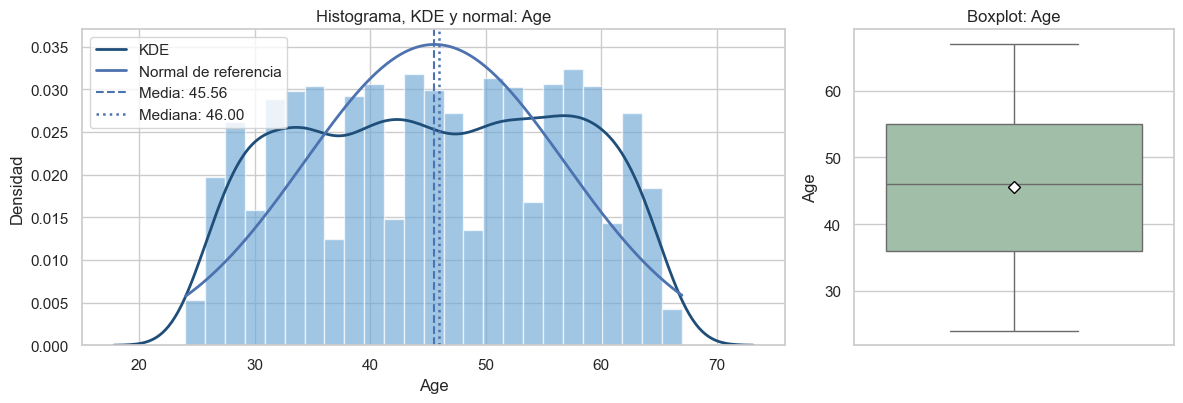

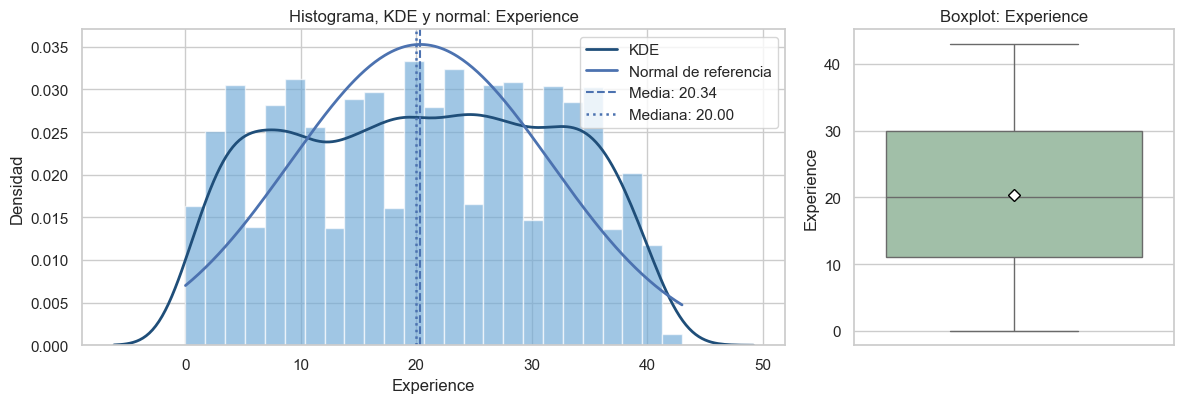

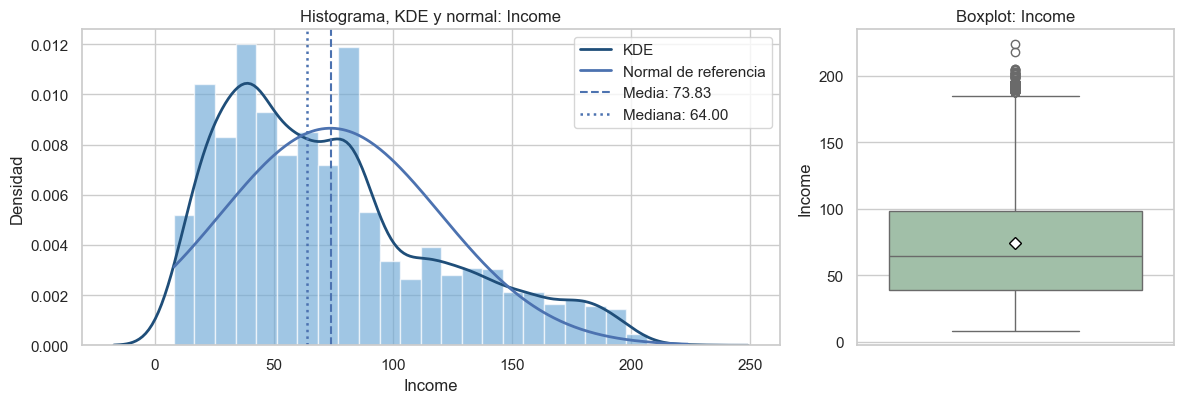

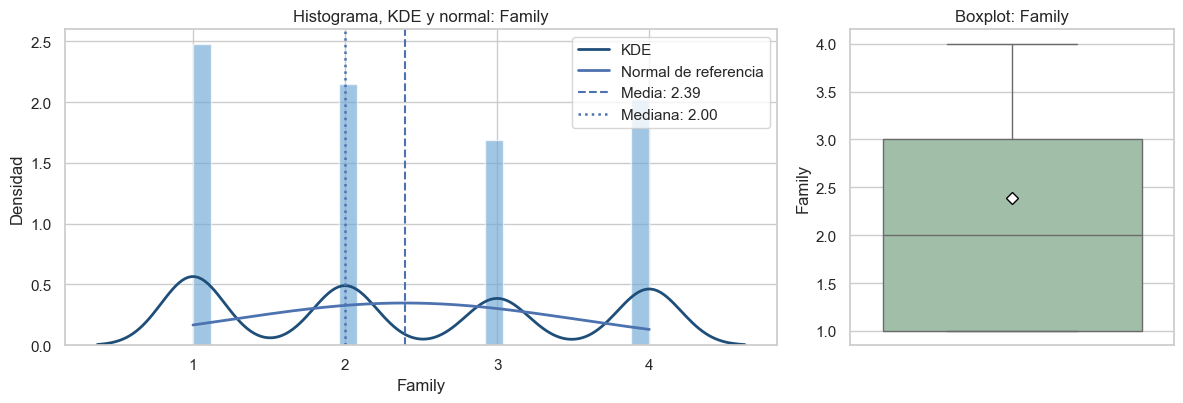

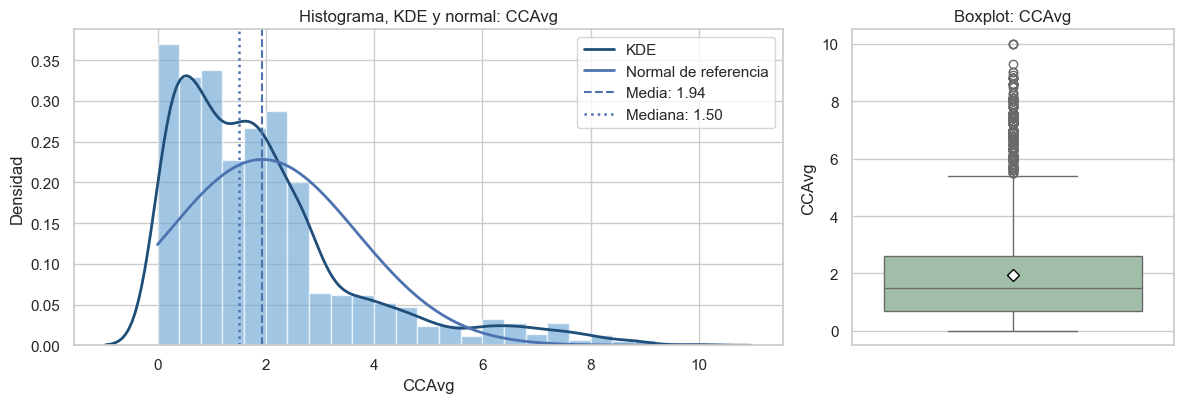

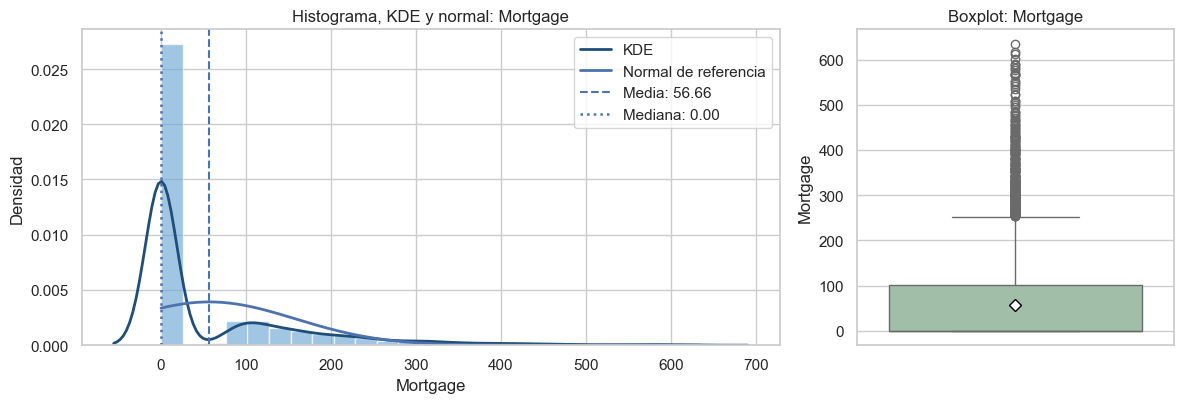

In [21]:
resumen_media_mediana = pd.DataFrame({
    'media': loan_df[num_cols].mean(),
    'mediana': loan_df[num_cols].median(),
    'diferencia_media_mediana': loan_df[num_cols].mean() - loan_df[num_cols].median(),
    'asimetría': loan_df[num_cols].skew()
})
display(resumen_media_mediana)

for columna in num_cols:
    valores = loan_df[columna].dropna().astype(float)
    media = valores.mean()
    mediana = valores.median()
    desviacion = valores.std(ddof=1)
    eje_x = np.linspace(valores.min(), valores.max(), 300)

    figura, ejes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [2.2, 1]})
    ejes[0].hist(valores, bins=25, density=True, color='#6EA8D6', alpha=0.65, edgecolor='white')
    sns.kdeplot(x=valores, color='#1F4E79', linewidth=2, ax=ejes[0], label='KDE')
    ejes[0].plot(eje_x, norm.pdf(eje_x, media, desviacion), linewidth=2, label='Normal de referencia')
    ejes[0].axvline(media, linestyle='--', linewidth=1.5, label=f'Media: {media:.2f}')
    ejes[0].axvline(mediana, linestyle=':', linewidth=1.8, label=f'Mediana: {mediana:.2f}')
    ejes[0].set_title(f'Histograma, KDE y normal: {columna}')
    ejes[0].set_ylabel('Densidad')
    ejes[0].legend()

    sns.boxplot(y=valores, color='#9CC4A5', showmeans=True, meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}, ax=ejes[1])
    ejes[1].set_title(f'Boxplot: {columna}')
    ejes[1].set_ylabel(columna)

    figura.tight_layout()
    plt.show()

**Interpretación.** La forma de los histogramas coincide con los indicadores numéricos. `Age` es amplia y casi simétrica; su media (45.56) y mediana (46) son prácticamente iguales. `Income` presenta cola derecha y una media (73.83) superior a la mediana (64). `Mortgage` concentra gran cantidad de ceros y pocos valores muy altos: su mediana es 0, pero la media alcanza 56.66, confirmando el sesgo positivo fuerte. `CCAvg` también está sesgada a la derecha. En general, cuando la media queda por encima de la mediana existe sesgo positivo; cuando queda por debajo, sesgo negativo; y cuando ambas casi coinciden, la distribución es aproximadamente simétrica.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

,count,unique,top,freq
ZIP Code,4941,467,94720,163
Education,4941,3,1,2079
Personal Loan,4941,2,0,4462
Securities Account,4941,2,0,4426
CD Account,4941,2,0,4640
Online,4941,2,1,2951
CreditCard,4941,2,0,3489


**Frecuencias de ZIP Code**

,frecuencia
ZIP Code,
94720,163
94305,123
95616,115
90095,71
93106,56
...,...
92694,1
94965,1
91024,1


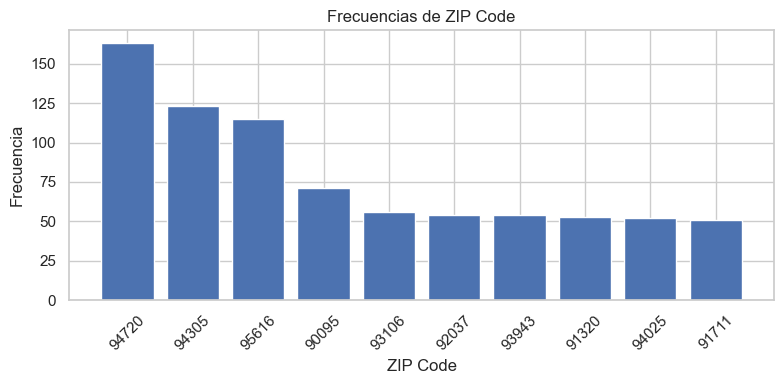

**Frecuencias de Education**

,frecuencia
Education,
1,2079
3,1477
2,1385


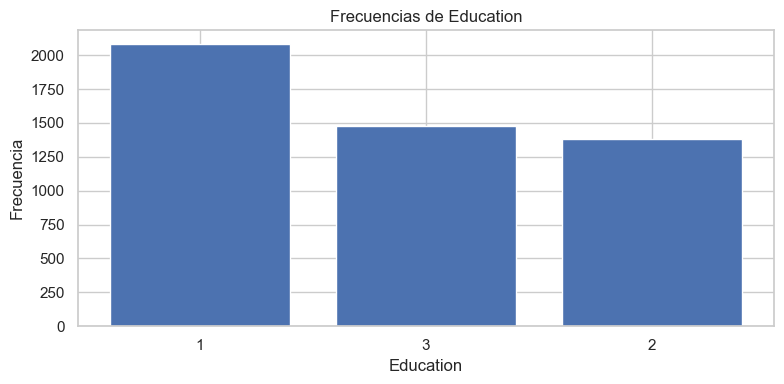

**Frecuencias de Personal Loan**

,frecuencia
Personal Loan,
0,4462
1,479


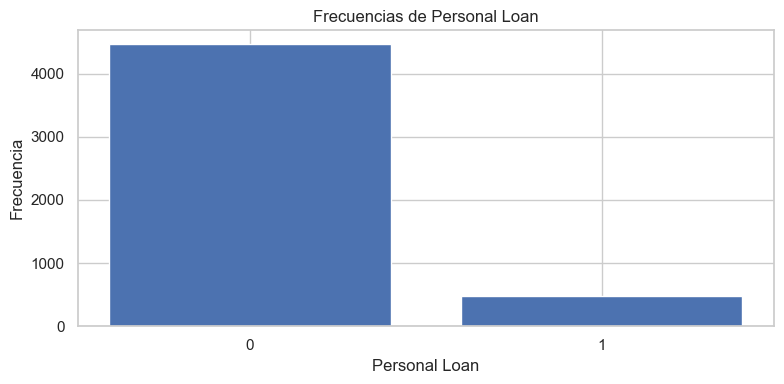

**Frecuencias de Securities Account**

,frecuencia
Securities Account,
0,4426
1,515


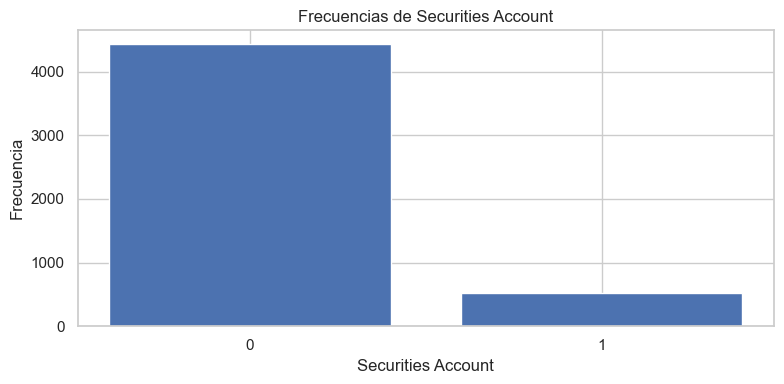

**Frecuencias de CD Account**

,frecuencia
CD Account,
0,4640
1,301


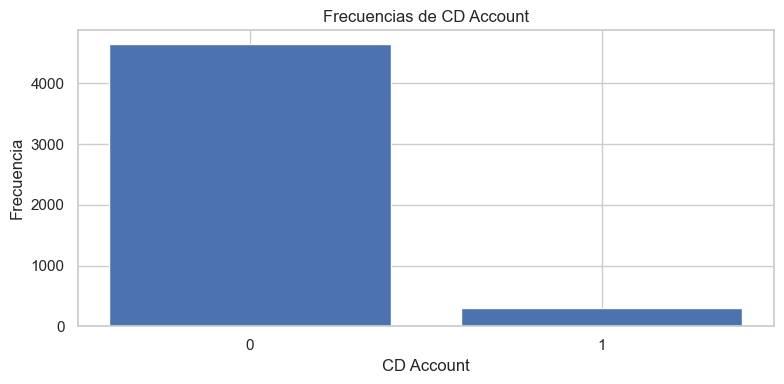

**Frecuencias de Online**

,frecuencia
Online,
1,2951
0,1990


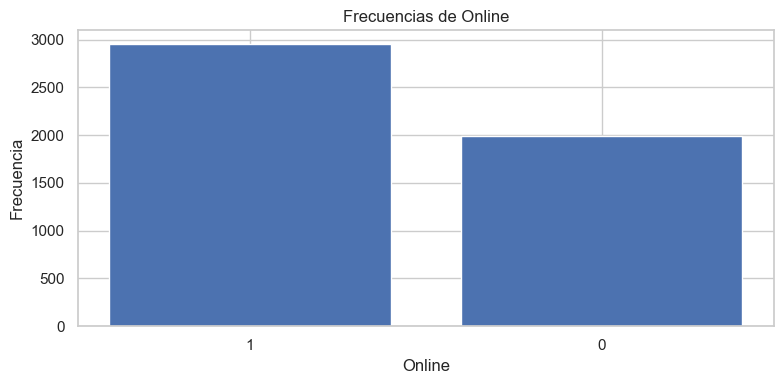

**Frecuencias de CreditCard**

,frecuencia
CreditCard,
0,3489
1,1452


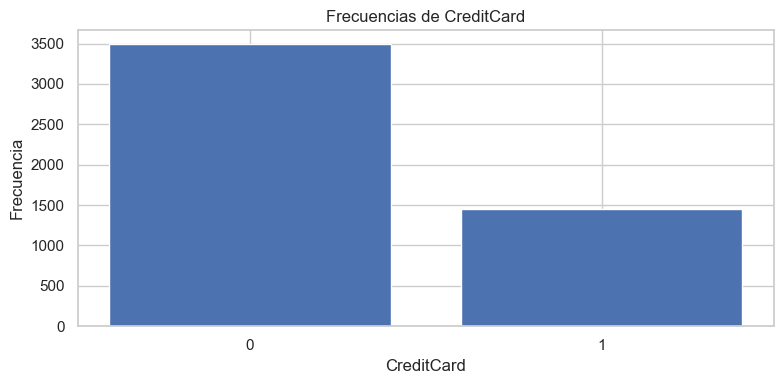

In [22]:
estadisticas_categoricas = loan_df[cat_cols].describe().T
display(estadisticas_categoricas)

for columna in cat_cols:
    display(Markdown(f'**Frecuencias de {columna}**'))
    frecuencias = loan_df[columna].value_counts(dropna=False)
    display(frecuencias.to_frame('frecuencia'))

    valores_grafica = frecuencias.head(10) if frecuencias.size > 10 else frecuencias
    figura, eje = plt.subplots(figsize=(8, 4))
    eje.bar(valores_grafica.index.astype(str), valores_grafica.values)
    eje.set_title(f'Frecuencias de {columna}')
    eje.set_xlabel(columna)
    eje.set_ylabel('Frecuencia')
    if frecuencias.size > 10:
        eje.tick_params(axis='x', rotation=45)
    figura.tight_layout()
    plt.show()

**Interpretación.** `ZIP Code` es la variable de mayor cardinalidad, por lo que se muestran únicamente sus diez códigos más frecuentes. Las variables binarias presentan dos categorías consistentes y el target está desbalanceado: **4,462 clientes no aceptaron el préstamo frente a 479 que sí lo aceptaron**. Este desbalance deberá considerarse más adelante al construir y evaluar modelos predictivos.

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

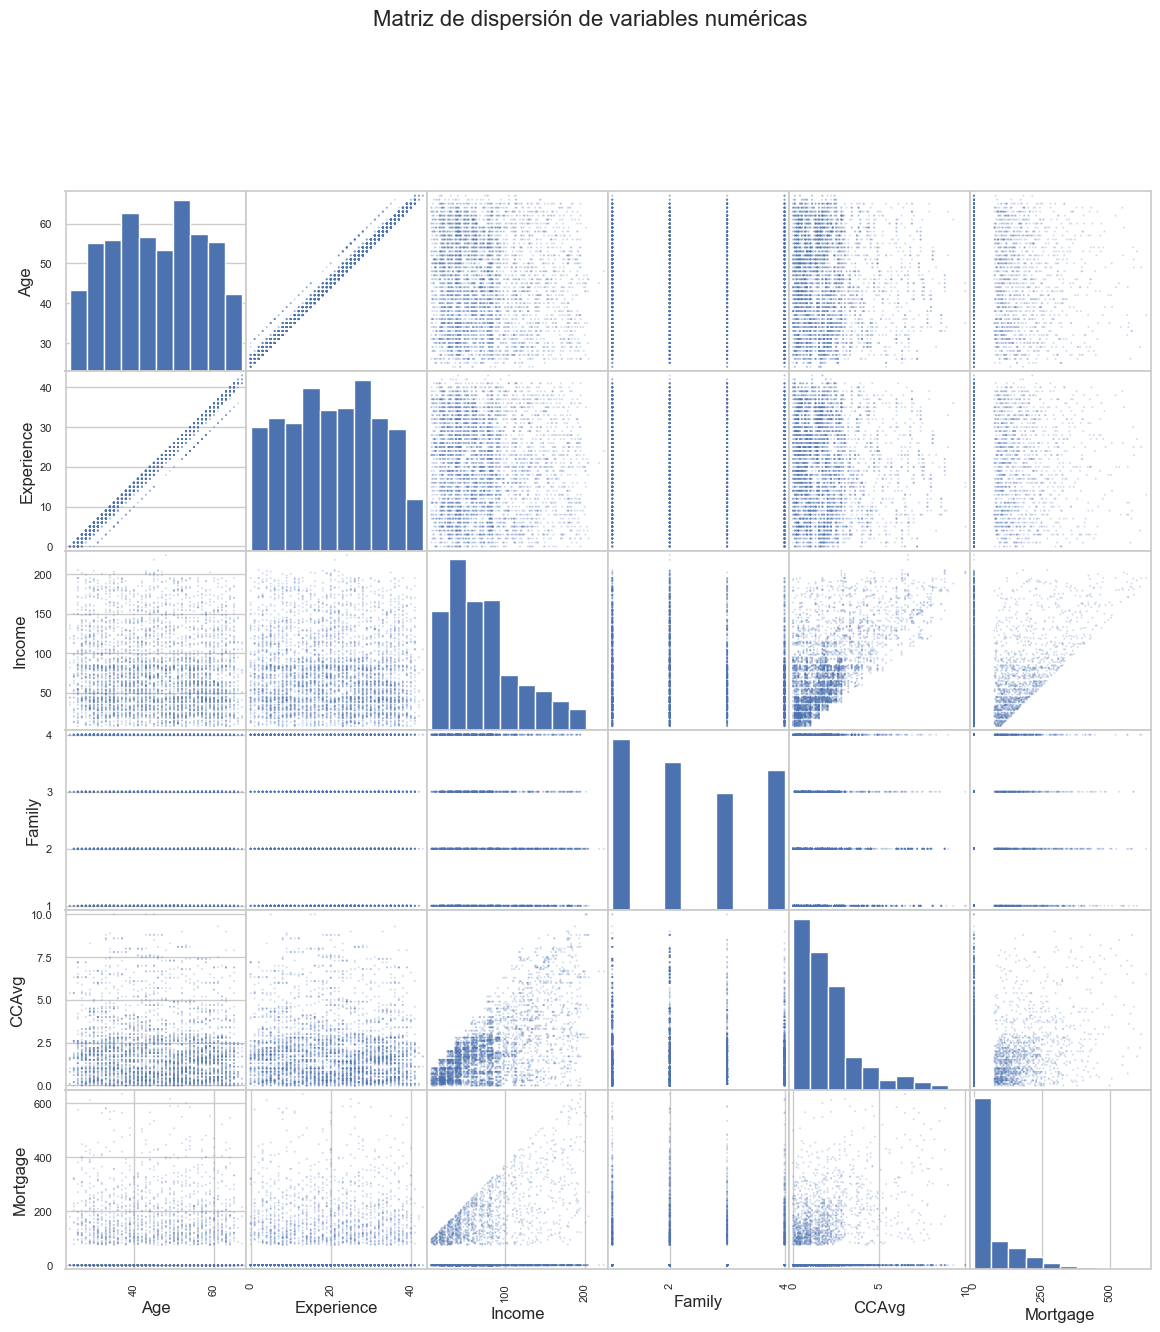

,Age,Experience,Income,Family,CCAvg,Mortgage
Age,1.000,0.994,-0.058,-0.040,-0.051,-0.015
Experience,0.994,1.000,-0.050,-0.046,-0.049,-0.013
Income,-0.058,-0.050,1.000,-0.156,0.646,0.207
Family,-0.040,-0.046,-0.156,1.000,-0.107,-0.020
CCAvg,-0.051,-0.049,0.646,-0.107,1.000,0.110
Mortgage,-0.015,-0.013,0.207,-0.020,0.110,1.000


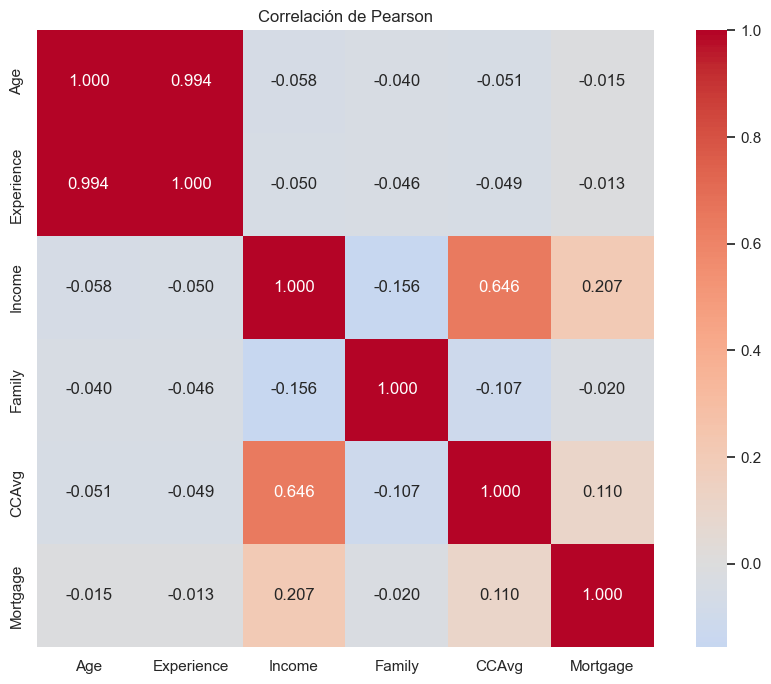

,correlación_pearson
Income vs CCAvg,0.646


In [23]:
matriz_dispersion = pd.plotting.scatter_matrix(
    loan_df[num_cols],
    figsize=(14, 14),
    diagonal='hist',
    alpha=0.25,
    s=8
)
plt.suptitle('Matriz de dispersión de variables numéricas', y=1.01, fontsize=16)
plt.show()

correlaciones = loan_df[num_cols].corr(method='pearson')
display(correlaciones)

figura, eje = plt.subplots(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, fmt='.3f', cmap='coolwarm', center=0, square=True, ax=eje)
eje.set_title('Correlación de Pearson')
figura.tight_layout()
plt.show()

correlacion_income_ccavg = correlaciones.loc['Income', 'CCAvg']
display(pd.DataFrame({'correlación_pearson': [correlacion_income_ccavg]}, index=['Income vs CCAvg']))

**Hallazgo.** La relación más fuerte es `Age`–`Experience` (r ≈ 0.994), algo esperable porque la experiencia laboral aumenta con la edad. Como par más relevante para el negocio se seleccionó `Income`–`CCAvg`: la nube de puntos muestra una tendencia positiva y Pearson confirma una correlación de aproximadamente **0.646**. El patrón coincide con lo observado visualmente: clientes con mayor ingreso tienden a registrar mayor gasto con tarjeta, aunque la dispersión demuestra que el ingreso no explica por sí solo todo el comportamiento de consumo.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


Age        Experience         Income         Family         \
                mean median       mean median    mean  median   mean median   
Personal Loan                                                                 
0             45.612 46.000     20.387 20.000  66.218  59.000  2.368  2.000   
1             45.077 45.000     19.856 20.000 144.706 142.000  2.616  3.000   

              CCAvg        Mortgage         
               mean median     mean median  
Personal Loan                               
0             1.725  1.400   51.898  0.000  
1             3.905  3.800  101.056  0.000

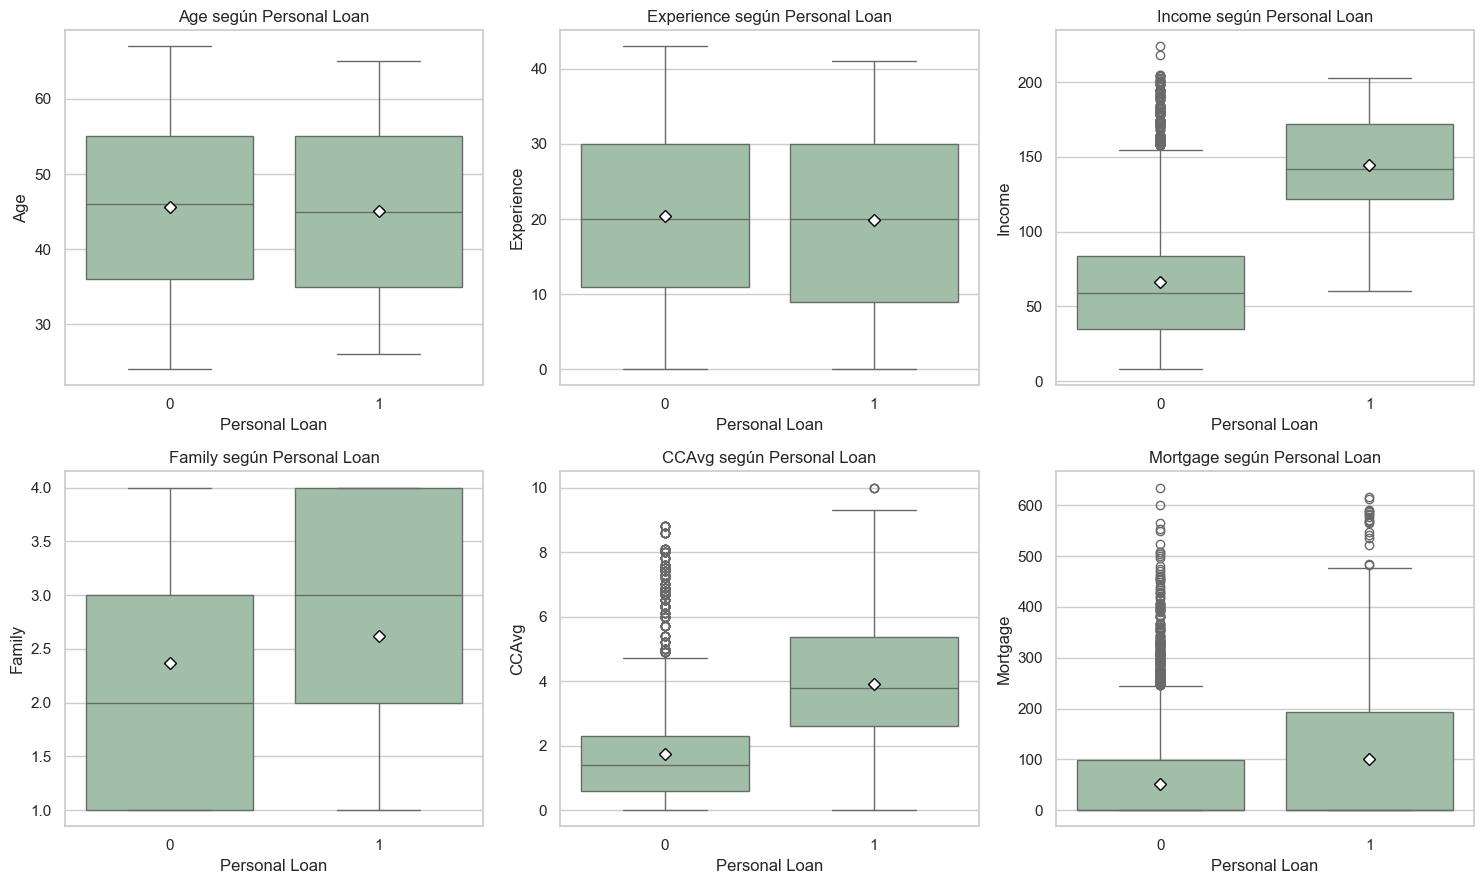

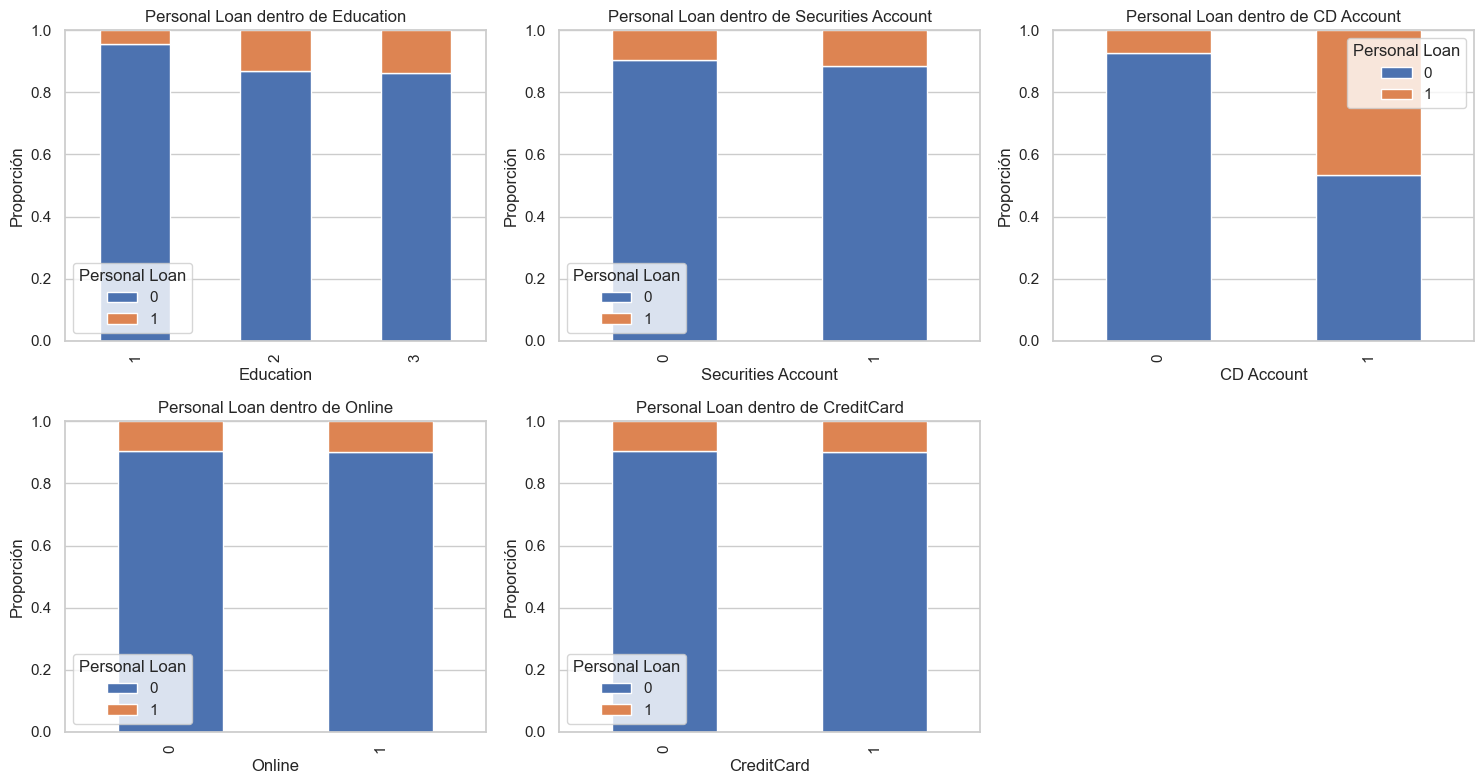

**Proporciones de Personal Loan dentro de Education**

Personal Loan,0,1
Education,,
1,0.955,0.045
2,0.869,0.131
3,0.861,0.139


**Proporciones de Personal Loan dentro de Securities Account**

Personal Loan,0,1
Securities Account,,
0,0.905,0.095
1,0.883,0.117


**Proporciones de Personal Loan dentro de CD Account**

Personal Loan,0,1
CD Account,,
0,0.927,0.073
1,0.535,0.465


**Proporciones de Personal Loan dentro de Online**

Personal Loan,0,1
Online,,
0,0.906,0.094
1,0.901,0.099


**Proporciones de Personal Loan dentro de CreditCard**

Personal Loan,0,1
CreditCard,,
0,0.904,0.096
1,0.902,0.098


In [24]:
resumen_numerico_target = loan_df.groupby('Personal Loan', observed=False)[num_cols].agg(['mean', 'median'])
display(resumen_numerico_target)

figura, ejes = plt.subplots(2, 3, figsize=(15, 9))
for columna, eje in zip(num_cols, ejes.ravel()):
    sns.boxplot(data=loan_df, x='Personal Loan', y=columna, color='#9CC4A5', showmeans=True, meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}, ax=eje)
    eje.set_title(f'{columna} según Personal Loan')
figura.tight_layout()
plt.show()

predictores_categoricos = [c for c in cat_cols if c not in ['ZIP Code', 'Personal Loan']]
proporciones_target = {}

figura, ejes = plt.subplots(2, 3, figsize=(15, 8))
for columna, eje in zip(predictores_categoricos, ejes.ravel()):
    tabla = pd.crosstab(loan_df[columna], loan_df['Personal Loan'], normalize='index')
    proporciones_target[columna] = tabla
    tabla.plot(kind='bar', stacked=True, ax=eje)
    eje.set_title(f'Personal Loan dentro de {columna}')
    eje.set_ylabel('Proporción')
    eje.set_ylim(0, 1)
    eje.legend(title='Personal Loan')

for eje in ejes.ravel()[len(predictores_categoricos):]:
    eje.set_visible(False)

figura.tight_layout()
plt.show()

for columna, tabla in proporciones_target.items():
    display(Markdown(f'**Proporciones de Personal Loan dentro de {columna}**'))
    display(tabla)

**Hallazgos respecto a Personal Loan.** Entre las variables numéricas, `Income` y `CCAvg` son las que mejor separan a los grupos: quienes aceptaron el préstamo tienen ingresos medios de aproximadamente **144.7 mil USD** frente a **66.2 mil USD**, y gasto mensual medio con tarjeta de **3.90 mil USD** frente a **1.72 mil USD**. `Age` y `Experience` muestran distribuciones muy similares entre ambos grupos. `Mortgage` tiene una media mayor entre quienes aceptaron, pero la mediana permanece en cero en los dos grupos, por lo que su señal está concentrada en una minoría.

Entre las variables categóricas, `CD Account` destaca: la aceptación del préstamo es cercana a **46.5%** entre clientes con certificado de depósito y sólo **7.3%** entre quienes no lo tienen. Los niveles educativos 2 y 3 también presentan proporciones de aceptación superiores al nivel 1. En contraste, `Online` y `CreditCard` muestran diferencias mínimas, por lo que parecen tener poca capacidad discriminante de manera aislada.